# Binary Classification

A companion to the handout of the same name. The setup cell below writes the three data files, so
nothing has to be downloaded first, and the cells run in order from the top.

The files hold customer records with four numeric columns (`age`, `income`, `tenure_months`,
`score`), three categorical ones (`region`, `plan`, `channel`) and the label `churn`, 1 for a customer
who left and 0 for one who stayed: 4960 training rows in `train.csv`, 1608 test rows in `test.csv`
and a second cohort of 3000 in `cohort2.csv`. The data is synthetic and seeded, so every number below
is reproducible.

In [ ]:
#@title Setup: write train.csv, test.csv and cohort2.csv  { display-mode: "form" }
# Writes the files every cell below reads: the training rows with their labels, the test rows and a second cohort.
import base64, gzip, os

_FILES = {
    "train.csv": (
        "..."
    ),
    "test.csv": (
        "..."
        "aVpH7XgJp8/2Ve6pCpSUWI9u8/8AhL3UXjARAQA="
    ),
    "cohort2.csv": (
        "..."
    ),
}

for _name, _blob in _FILES.items():
    if not os.path.exists(_name):
        with open(_name, "wb") as f:
            f.write(gzip.decompress(base64.b64decode(_blob)))
    print(_name, os.path.getsize(_name) // 1024, "KB")

train.csv 210 KB
test.csv 68 KB
cohort2.csv 127 KB


### The three files

`train`, `test` and `cohort` hold the rows of the three files as dictionaries, as
`csv.DictReader` returns them, and `ytr`, `yte` and `y2` their labels as integer arrays.

In [ ]:
import copy, csv
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

def read(name):
    with open(name, newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

train, test, cohort = read("train.csv"), read("test.csv"), read("cohort2.csv")
ytr, yte, y2 = (np.array([int(r["churn"]) for r in rows]) for rows in (train, test, cohort))
print(len(train), "training rows,", len(test), "test rows,", len(cohort), "rows of the second cohort")

4960 training rows, 1608 test rows, 3000 rows of the second cohort


## 01 Preprocessing fitted on the training split

A network takes one matrix of floats with no gaps. Four steps produce it from the table: the gaps of each numeric column filled with the column's median, the numeric columns standardised, each categorical column one-hot encoded, and the blocks joined side by side. Every number the steps use is computed on the training rows.

In [ ]:
NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {"region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
              "plan": ["basic", "standard", "premium", "legacy"],
              "channel": ["shop", "phone", "online"]}

def column(rows, name):
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in rows])

medians = {c: float(np.nanmedian(column(train, c))) for c in NUMERIC}
print(medians)     # -> {'age': 43.0, 'income': 27555.325, 'tenure_months': 23.0, 'score': 57.8}

def numeric_block(rows):
    cols = []
    for c in NUMERIC:
        v = column(rows, c)
        cols.append(np.where(np.isnan(v), medians[c], v))         # 1. gaps filled
    return np.stack(cols, axis=1)                                 # (n rows, 4)

num_train = numeric_block(train)            # (4960, 4)
mean = num_train.mean(axis=0)
std = num_train.std(axis=0)
np.set_printoptions(suppress=True)          # plain decimals rather than powers of ten
print(mean.round(2))                        # -> [   42.93 31040.41    25.52    57.55]
print(std.round(2))                         # -> [   13.11 14632.47    17.87    12.85]

def features(rows):
    blocks = [(numeric_block(rows) - mean) / std]                 # 2. standardised
    for cat in CATEGORICAL:                                       # 3. one-hot
        v = np.array([r[cat] for r in rows])
        blocks.append(np.stack([(v == name).astype(float) for name in CATEGORIES[cat]],
                               axis=1))
    return np.concatenate(blocks, axis=1)                         # 4. joined

xtr = features(train)       # 4 numeric + 6 + 4 + 3 one-hot columns
xte = features(test)        # the same 17 columns, in the same order
print((xtr.shape, xte.shape))        # -> ((4960, 17), (1608, 17))
print(xtr[:, 0].mean())     # -> 0.0    age, on the training rows
print(xtr[:, 0].std())      # -> 1.0

{'age': 43.0, 'income': 27555.325, 'tenure_months': 23.0, 'score': 57.8}
[   42.93 31040.41    25.52    57.55]
[   13.11 14632.47    17.87    12.85]
((4960, 17), (1608, 17))
2.4066770082196944e-16
1.0000000000000056


`np.stack` puts the four filled columns side by side as the columns of one `(n, 4)` array, and `np.concatenate` joins the standardised block and the three one-hot blocks along the columns. `CATEGORIES` fixes the order of the one-hot columns, so that column 7 means Eastfield in every split, including a split in which no customer is from Eastfield.

### Fitting on the training split

The medians, the means and the standard deviations are computed on `train` and then applied unchanged to `test`. Recomputing them on the test split would let the held-out rows influence their own preprocessing, and the measured accuracy would no longer be the accuracy of the model on rows it has never seen. `features` takes `rows` as its argument and reads `medians`, `mean` and `std` from the training fit, so the statistics cannot come from the rows being transformed.

### Indicator columns

In [ ]:
for c in ["age", "income", "score"]:           # the numeric columns with gaps
    gap = np.isnan(column(train, c))
    print(f"{c:<7}{gap.sum():4} gaps   churn rate {ytr[gap].mean():.3f} with a gap, "
          f"{ytr[~gap].mean():.3f} without")
# age     303 gaps   churn rate 0.502 with a gap, 0.500 without
# income  404 gaps   churn rate 0.488 with a gap, 0.501 without
# score   213 gaps   churn rate 0.498 with a gap, 0.500 without

age     303 gaps   churn rate 0.502 with a gap, 0.500 without
income  404 gaps   churn rate 0.488 with a gap, 0.501 without
score   213 gaps   churn rate 0.498 with a gap, 0.500 without


Filling a gap also erases the fact that the value was missing, which an extra 0/1 indicator column per filled column would keep. In these training rows the churn rate hardly depends on whether a value was missing, so the three indicators would add three nearly uninformative columns, and they are left out of this matrix.

### Min-max scaling

In [ ]:
lo, hi = num_train.min(axis=0), num_train.max(axis=0)    # (4,) each, from the training rows
minmax = (num_train - lo) / (hi - lo)                    # every training column onto [0, 1]
print(np.median(minmax[:, 1]))          # -> 0.157   the median income
print(np.quantile(minmax[:, 1], 0.95))  # -> 0.399

0.1569307853524218
0.3986819235714175


Min-max scaling is the other common choice. It maps each column's training minimum to 0 and its maximum to 1, so it is set by the two most extreme values of the column. A column with a long tail ends up crowded at one end: income's training maximum is 142611, and after the scaling the median income is 0.157 and 95 per cent of the incomes are below 0.399. Rows from other splits can land outside [0, 1]. The matrices `xtr` and `xte` are standardised; with either scaling, the two numbers per column come from the training rows only.

## 02 Splits and class balance

Three sets of rows, each with its own use: training rows to fit the parameters on, validation rows to make decisions with, and test rows to measure the final model once. Every set is checked for its class balance before anything is trained.

### A validation split

In [ ]:
rng = np.random.default_rng(42)
idx = rng.permutation(len(train))          # 0 to 4959 in a random order
val_rows = [train[i] for i in idx[:992]]   # the first fifth: validation
fit_rows = [train[i] for i in idx[992:]]   # the rest: fitting
print((len(fit_rows), len(val_rows)))      # -> (3968, 992)

(3968, 992)


The test rows are used to measure the final model, and anything chosen by looking at them, such as the number of epochs, makes that measurement optimistic. A validation set is a part of the training rows held back for those choices. `np.random.default_rng(42)` creates a random number generator seeded with 42, and its `permutation(n)` returns the integers 0 to n - 1 in a random order. Slices of one permutation do not overlap, their sizes are fixed, and their rows are random. Splitting a file in its own order instead takes whatever order it was written in, by date, by customer number or by label, and the two parts then differ in a systematic way.

### Class balance

In [ ]:
print(np.bincount(ytr))     # -> [2480 2480]   training rows: stayed, left
print(np.bincount(yte))     # -> [804 804]     test rows
print(np.bincount(y2))      # -> [1500 1500]   second cohort

[2480 2480]
[804 804]
[1500 1500]


In the full customer register 3284 of 9000 customers left, 36 per cent, and here every set is exactly half and half. The rows were sampled that way: each set contains the same number of rows from both classes. This is **undersampling**, one of three standard responses to an imbalanced label:

- **Undersampling.** Keep every row of the smaller class and a random sample of the same size from the larger one. Rows of the larger class are discarded.
- **Oversampling.** Draw rows of the smaller class with replacement until the classes are the same size. Rows of the smaller class are repeated.
- **Loss weighting.** Keep every row, and give the loss terms of the smaller class more weight.

In [ ]:
weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(5716 / 3284))   # 1.741

`pos_weight` multiplies the loss term of every row whose label is 1. Set to the ratio of stayed to left customers in the register, it makes the two classes contribute the same total weight to the average loss. With balanced sets, as here, it stays at its default of 1. The class balance of the test rows also sets the baseline: always answering "stayed" scores 0.500 on these test rows, and would score 0.635 on the full register.

## 03 Logistic regression and an MLP

Two models for the same label: logistic regression, a single weighted sum of the 17 features, and an MLP with two hidden layers. Both end in one output per row.

In [ ]:
class LogReg(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.linear = nn.Linear(n_in, 1)        # one weighted sum, no hidden layer

    def forward(self, x):                       # (n, n_in) -> (n,)
        return self.linear(x).squeeze(-1)

class Net(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(n_in, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1))

    def forward(self, x):                       # (n, n_in) -> (n,)
        return self.stack(x).squeeze(-1)

torch.manual_seed(42)
net = Net(17)
print(sum(p.numel() for p in LogReg(17).parameters()))     # -> 18
print(sum(p.numel() for p in net.parameters()))     # -> 1121

print([(name, tuple(p.shape)) for name, p in net.named_parameters()])
# -> [('stack.0.weight', (32, 17)), ('stack.0.bias', (32,)),
#     ('stack.2.weight', (16, 32)), ('stack.2.bias', (16,)),
#     ('stack.4.weight', (1, 16)), ('stack.4.bias', (1,))]

18
1121
[('stack.0.weight', (32, 17)), ('stack.0.bias', (32,)), ('stack.2.weight', (16, 32)), ('stack.2.bias', (16,)), ('stack.4.weight', (1, 16)), ('stack.4.bias', (1,))]


Logistic regression is one weighted sum of the 17 features plus a bias, 18 parameters, and the sigmoid of the sum is read as the probability that the label is 1. `Net` puts two hidden layers, of 32 and 16 units with ReLU, in front of the same kind of last layer: 17 by 32 plus 32, then 32 by 16 plus 16, then 16 by 1 plus 1, 1121 parameters. Both return one number per row. Their last layer gives an output of shape `(n, 1)`, and `squeeze(-1)` removes the last axis, so that the output has the shape of the labels, `(n,)`.

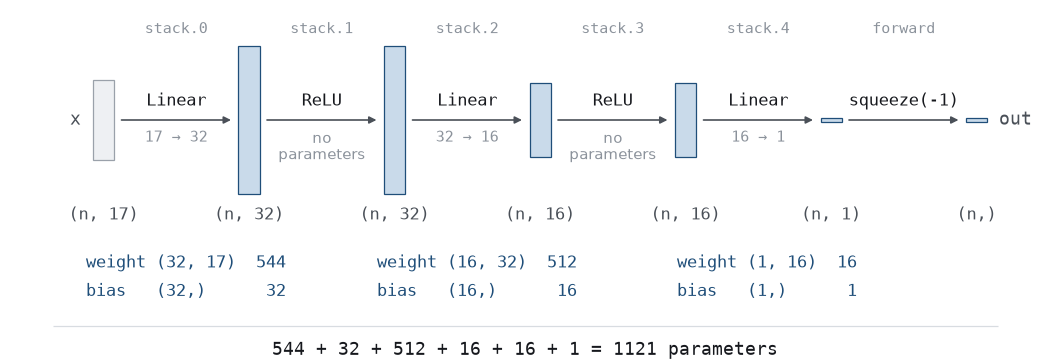

Net(17) applied to an input of shape (n, 17), one bar per tensor, its height the length of the last axis. Each nn.Linear(a, b) holds a weight of shape (b, a) and a bias of shape (b,); the ReLU layers hold no parameters, and the 6 tensors add up to 1121.

### Test accuracy of the two models

Trained for 40 epochs with Adam at a learning rate of 0.001 on minibatches of 128 rows, logistic regression scores 0.664 on the test rows and 0.680 on the second cohort, against 0.659 and 0.678 for the MLP. Repeated with the seeds 0 to 4, the MLP scores between 0.652 and 0.660 on the test rows and logistic regression between 0.664 and 0.667, higher with every seed. On this table the hidden layers add nothing measurable, so the 18-parameter model is the baseline a deeper network is compared against.

**Try it.** Count the parameters of `Net` with hidden layers of 64 and 32 units instead of 32 and 16.

## 04 Logits and BCEWithLogitsLoss

Both models end in a linear layer with one output and nothing after it. The loss turns that output and the true label into a single number measuring how wrong the model currently is.

The final `nn.Linear(16, 1)` of `Net`, like the single layer of `LogReg`, produces one number per row. That number is a **logit**. It can be any real number, and `sigmoid` maps it to a probability between 0 and 1; the logit and the probability describe the same prediction.

In [ ]:
print(torch.sigmoid(torch.tensor([0.0, 2.0, -2.0])))   # -> tensor([0.5000, 0.8808, 0.1192])

tensor([0.5000, 0.8808, 0.1192])


A logit of 0 is a probability of a half, positive logits are above a half, negative below. The last layer has no sigmoid because the loss, `nn.BCEWithLogitsLoss`, applies the sigmoid itself, in a numerically stable form.

### BCEWithLogitsLoss

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()                # takes logits
x = torch.tensor(xtr, dtype=torch.float32)      # (4960, 17)
y = torch.tensor(ytr, dtype=torch.float32)      # (4960,) of 0.0 / 1.0, a float
print(loss_fn(net(x), y).item())                # -> 0.6930   (n,) and (n,) -> one number

0.6930099725723267


For one row with predicted probability `p` and label 1, the **binary cross entropy** is `-log(p)`; for label 0 it is `-log(1 - p)`. It is small when the probability given to the true label is close to 1, and grows without limit as that probability goes to 0. The loss is its mean over the rows. `nn.BCELoss()(torch.sigmoid(z), y)` computes it from probabilities. `nn.BCEWithLogitsLoss()(z, y)` combines the sigmoid and the loss in one class and uses the log-sum-exp trick, which keeps the exponential from overflowing. The label argument is a float of 0.0 or 1.0, not an integer.

In [ ]:
for v in [-20.0, -40.0, -100.0]:                # one row with label 1, ever more wrong
    z1 = torch.tensor([v], requires_grad=True)
    z2 = torch.tensor([v], requires_grad=True)
    loss1 = nn.BCEWithLogitsLoss()(z1, torch.ones(1))           # combined
    loss2 = nn.BCELoss()(torch.sigmoid(z2), torch.ones(1))      # sigmoid, then the loss
    loss1.backward()
    loss2.backward()
    print(f"logit {v:6.1f}   losses {loss1.item():5.1f} {loss2.item():5.1f}   "
          f"gradients {z1.grad.item():4.1f} {z2.grad.item():9.6f}")
# logit  -20.0   losses  20.0  20.0   gradients -1.0 -1.000000
# logit  -40.0   losses  40.0  40.0   gradients -1.0 -0.000004
# logit -100.0   losses 100.0 100.0   gradients -1.0 -0.000000

logit  -20.0   losses  20.0  20.0   gradients -1.0 -1.000000
logit  -40.0   losses  40.0  40.0   gradients -1.0 -0.000004
logit -100.0   losses 100.0 100.0   gradients -1.0 -0.000000


The two give the same loss and different gradients. For a row with label `y` the gradient of the loss with respect to the logit is `sigmoid(z) - y`, which for label 1 tends to -1 as the logit goes to minus infinity, and the combined version computes it in that form. The separate version differentiates through the probability `sigmoid(z)`, which at a logit of -40 is 4.2e-18, and returns -0.000004. At -100 the sigmoid underflows to exactly 0, and the gradient is 0; the loss stays at 100 because `BCELoss` clamps its logarithms at -100. A row the model gets badly wrong then produces almost no update, or none.

### The loss before training

An untrained network on a balanced binary problem should start near `ln 2 = 0.6931`, the loss of a model that gives every row a probability of a half. The untrained `Net(17)` above gives 0.6930 on the 4960 training rows, and 0.6912 on the first minibatch of the training loop. A first loss far from `ln 2` points to a problem before training has begun, such as wrong labels or unscaled features.

## 05 The training loop

The four statements of a training step, inside a loop over minibatches and a loop over epochs.

In [ ]:
torch.manual_seed(42)                           # the same weights and batches on every run
net = Net(xtr.shape[1])
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

x = torch.tensor(xtr, dtype=torch.float32)      # (4960, 17)
y = torch.tensor(ytr, dtype=torch.float32)      # (4960,)

losses = []
for epoch in range(40):
    perm = torch.randperm(len(x))               # reshuffle every epoch
    for i in range(0, len(x), 128):
        b = perm[i:i + 128]                     # the row indices of one minibatch
        opt.zero_grad()                         # 1. clear last step's gradients
        loss = loss_fn(net(x[b]), y[b])         # 2. forward pass and loss
        loss.backward()                         # 3. gradients of the loss
        opt.step()                              # 4. update the parameters from .grad
        losses.append(loss.item())              # the value, as a Python float

| statement | effect | effect if omitted |
|---|---|---|
| `opt.zero_grad()` | Sets every `.grad` to `None` | Each step follows the sum of all earlier gradients; the loss soon stops falling |
| `loss = loss_fn(net(x), y)` | Predicts, then scores the prediction | Nothing to differentiate |
| `loss.backward()` | Fills every `.grad` | `.grad` stays `None`, so `step()` changes nothing |
| `opt.step()` | Updates parameters from `.grad` | Gradients are computed and discarded; the parameters never change |

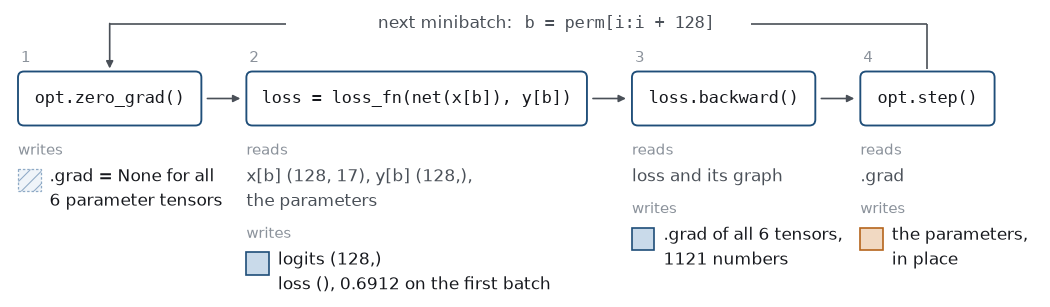

The four statements of one training step, repeated for every minibatch. opt.zero_grad() sets every .grad to None, the forward pass and the loss produce 128 logits and one number, loss.backward() fills .grad for all 1121 parameters, and opt.step() changes the parameters using .grad.

### net.parameters()

`net.parameters()` yields every tensor the module registered. The optimizer holds references to them, so `step()` can change them in place and the model computes with the changed values. Only registered tensors are handed to the optimizer: a layer that was never registered, such as one kept in a plain Python list, is never trained, and no error is raised.

### Minibatches

One step per row makes 4960 steps per epoch, each computed from a single row. One step per epoch over all 4960 rows makes 40 steps in 40 epochs. A batch of 128 rows, as here, makes 39 steps per epoch, each using an estimate of the gradient from a sample of rows; batch sizes from 32 to 256 are common. `torch.randperm` reshuffles every epoch so the batches differ each time.

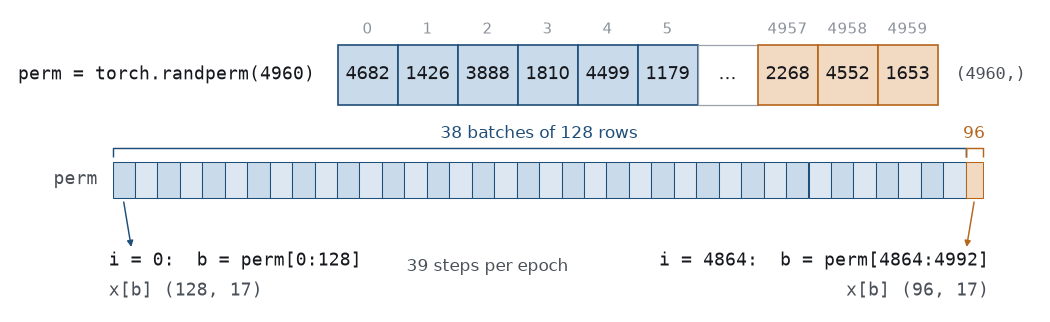

The first epoch's torch.randperm(4960) cut into batches by perm[i:i + 128]: 38 batches of 128 row indices and a last one of 96, where the slice stops at the end of perm. Each batch selects its rows of x for one step.

### Recording and plotting the loss

`loss.item()` returns the value of a one-element tensor as a Python float. Appending the tensor itself would also keep a reference to its part of the graph through `grad_fn`; the float is only the number. 40 epochs of 39 batches give 1560 values, the last batch of each epoch holding the 96 rows left over from 38 batches of 128.

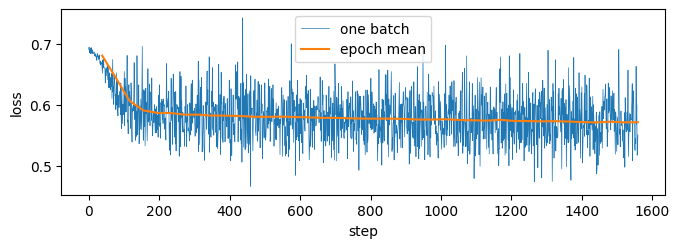

In [ ]:
plt.figure(figsize=(7, 2.6))
plt.plot(losses, linewidth=0.5, label="one batch")
means = np.array(losses).reshape(40, 39).mean(axis=1)     # (1560,) -> (40, 39) -> (40,)
plt.plot(np.arange(38, 1560, 39), means, label="epoch mean")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.tight_layout()
plt.show()

`plt.plot(v)` draws a line through the values of `v` against 0, 1, 2 and so on, and `plt.plot(x, v)` takes the x positions explicitly; here the epoch means are drawn at the last step of each epoch. `reshape(40, 39)` puts one epoch per row, so the mean along axis 1 is the mean loss of each epoch.

### Reading the loss

The loss varies from batch to batch, because each batch is a different sample of rows. The first batch gives 0.6912 and the last 0.5512. The epoch means fall from 0.681 to 0.572, quickly in the first three epochs and slowly after that. A loss that rises steadily usually means the learning rate is too high; one that does not move usually means a missing `backward()`, a missing `step()`, or unscaled features.

**Try it.** Run the loop with `lr=1e-2` and with `lr=1e-4`, and plot the epoch means of the three runs together.

## 06 Dataset and DataLoader

The shuffling and slicing of the training loop, moved out of it into two objects: a `Dataset`, which returns one row, and a `DataLoader`, which shuffles the rows and stacks them into batches. A `Dataset` needs exactly the two methods that make any object behave like a sequence.

In [ ]:
from torch.utils.data import Dataset, DataLoader

class Rows(Dataset):
    def __init__(self, x, y):
        self.x, self.y = x, y

    def __len__(self):                      # how many rows there are
        return len(self.x)

    def __getitem__(self, i):               # ONE row, as a tuple
        return self.x[i], self.y[i]

The class returns one row and does no batching or shuffling; the `DataLoader` adds both. Ten rows of one feature show it:

In [ ]:
x10 = torch.arange(10.0).reshape(10, 1)     # 10 rows of 1 feature, x10[i] = i
y10 = torch.arange(10.0)                    # 10 targets, y10[i] = i
ds = Rows(x10, y10)
print(len(ds))          # -> 10
print(ds[3])            # -> (tensor([3.]), tensor(3.))   one row, through __getitem__

dl = DataLoader(ds, batch_size=4, shuffle=True)
print(len(dl))          # -> 3     batches of 4, 4 and 2
print([tuple(xb.shape) for xb, yb in dl])      # -> [(4, 1), (4, 1), (2, 1)]
print(len(DataLoader(ds, batch_size=4, drop_last=True)))     # -> 2   the short batch discarded

10
(tensor([3.]), tensor(3.))
3
[(4, 1), (4, 1), (2, 1)]
2


The loader stacks the tuples `__getitem__` returns into batched tensors, reshuffles every epoch when `shuffle=True`, and yields until the rows run out. The last batch is short unless `drop_last=True`, which matters when a layer needs a fixed batch size or when a short final batch would make a running average jump.

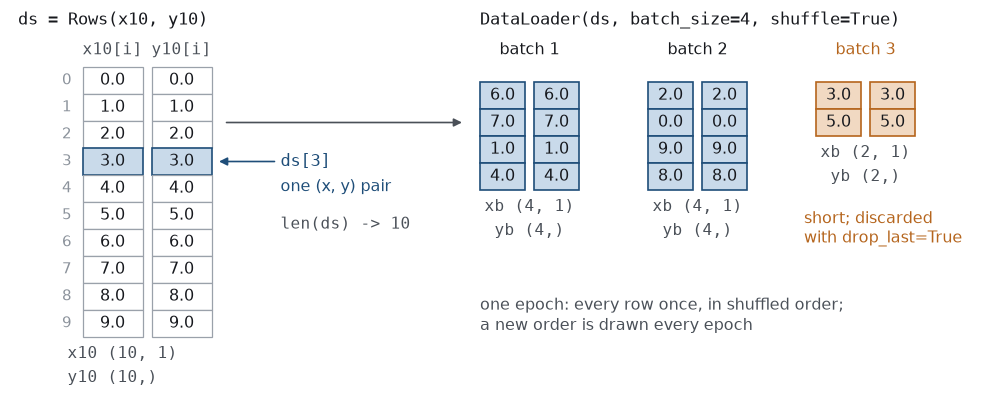

Left: ds holds 10 pairs, here with x10[i] = y10[i] = i, and ds[i] returns one of them. Right: one shuffled epoch of DataLoader(ds, batch_size=4, shuffle=True), which stacks the pairs into batches of 4, 4 and 2 rows.

### The training loop with a DataLoader

In [ ]:
loader = DataLoader(Rows(x, y), batch_size=128, shuffle=True)
print(len(loader))      # -> 39   batches per epoch

torch.manual_seed(42)
net = Net(17)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
for epoch in range(40):
    for xb, yb in loader:                   # shuffling and batching, both handled
        opt.zero_grad()
        loss = loss_fn(net(xb), yb)
        loss.backward()
        opt.step()
print(round(loss.item(), 4))   # -> 0.5600   the last batch

39
0.56


The four statements are unchanged; `torch.randperm` and the index arithmetic are no longer in the loop. The loader draws its own random order, so with the same seed its batches, and the loss of its last batch, differ from those of the hand-written loop, which ends at 0.5512. For tensors already in memory, `TensorDataset(x, y)` from the same module is the same thing without writing the class. Writing the class lets `__getitem__` read a file, decode an image, or apply a transformation one row at a time, as data too large for memory requires.

### A generator of minibatches

In [ ]:
def minibatches(n, size):
    perm = torch.randperm(n)                # a new order on every call
    for i in range(0, n, size):
        yield perm[i:i + size]

torch.manual_seed(42)                       # the same start as the hand-written loop
net = Net(17)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
for epoch in range(40):
    for b in minibatches(len(x), 128):
        opt.zero_grad()
        loss = loss_fn(net(x[b]), y[b])
        loss.backward()
        opt.step()
print(round(loss.item(), 4))   # -> 0.5512   the last batch, as in the hand-written loop

0.5512


The shuffling and slicing of the hand-written loop can also move into a generator function, which leaves only the four statements in the loop. Every call of `minibatches` draws a new order with `torch.randperm`, so with the same seed it produces exactly the batches, the losses and the trained weights of the hand-written loop.

## 07 Evaluation

A number for how good the model is, computed on rows it has never been trained on, and compared against the score of a model that always answers the same thing.

In [ ]:
def predict(matrix):
    with torch.no_grad():                               # no gradient recording
        logits = net(torch.tensor(matrix, dtype=torch.float32))
        return (torch.sigmoid(logits) > 0.5).long().numpy()

pred = predict(xte)                 # (1608,) of 0 / 1
print((pred == yte).mean())         # -> 0.6586   accuracy on the test rows

0.6585820895522388


`torch.no_grad()` because nothing is being learned, `torch.sigmoid` to turn logits into probabilities, and **a threshold of 0.5** to turn probabilities into answers. The threshold can be changed: raising it predicts churn less often, finding fewer of the churners and making fewer false alarms.

### Accuracy against the base rate

The accuracy is compared with simpler rules on the same test rows, which are half churners and half not:

| model | accuracy |
|---|---|
| Always answering "no churn" | 0.500 |
| Answering at random | 0.500 |
| Logistic regression, test split | 0.664 |
| The network above, test split | 0.659 |
| The same network, a second cohort of 3000 | 0.678 |

On an *unbalanced* split where 80 per cent do not churn, the constant answer scores 0.80, and a model at 0.78 is below it. An accuracy can be compared with the constant answer only when the class balance is known.

### The second cohort

In [ ]:
print((predict(features(cohort)) == y2).mean())    # -> 0.678

0.678


The same trained model, applied to 3000 rows from a different group with no retraining, scores 0.678 against 0.659 on the test rows, so its accuracy is not specific to the rows it was evaluated on.

### Preprocessing statistics and predicted class counts

- **Preprocessing statistics from the training rows only.** The medians, means and standard deviations are computed on the training rows; a statistic computed over the whole table before the split also includes the test rows.
- **Predicted class counts.** A model that predicts a single class for every row can still reach a high accuracy on an unbalanced split; `np.bincount(pred)` shows how many rows were given each class.

**Try it.** Raise the threshold in `predict` from 0.5 to 0.6 and compare `np.bincount(pred)` with the counts at 0.5.

## 08 Validation and early stopping

The training loss measures how well the network fits the rows it is trained on. The validation loss, computed after every epoch on rows it is never trained on, measures whether that fit holds on new rows, and is used to choose how long to train.

In [ ]:
medians = {c: float(np.nanmedian(column(fit_rows, c))) for c in NUMERIC}
num_train = numeric_block(fit_rows)
mean, std = num_train.mean(axis=0), num_train.std(axis=0)

xf, xv = features(fit_rows), features(val_rows)          # (3968, 17), (992, 17)
yf = np.array([int(r["churn"]) for r in fit_rows])
yv = np.array([int(r["churn"]) for r in val_rows])
x, y = torch.tensor(xf, dtype=torch.float32), torch.tensor(yf, dtype=torch.float32)
xv_t, yv_t = torch.tensor(xv, dtype=torch.float32), torch.tensor(yv, dtype=torch.float32)

The medians, means and standard deviations are fitted again on `fit_rows` alone, so that nothing about the validation rows reaches the model, and both sets are converted to tensors once.

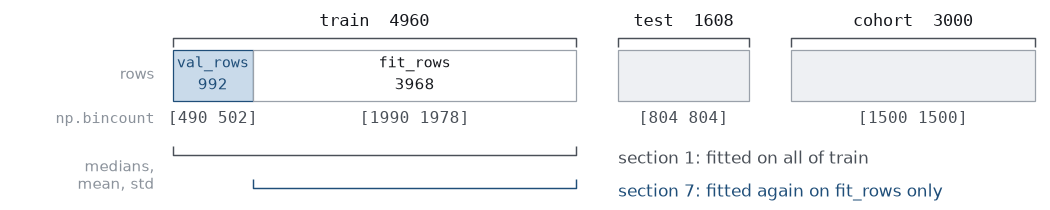

The rows of the three files to scale, with np.bincount of the labels of each part as [stayed left]. The brackets mark the rows the medians, means and standard deviations are computed from.

### Training and validation loss per epoch

In [ ]:
def train_epoch(net, opt, x, y):
    net.train()
    perm = torch.randperm(len(x))
    losses = []
    for i in range(0, len(x), 128):
        b = perm[i:i + 128]
        opt.zero_grad()
        loss = loss_fn(net(x[b]), y[b])
        loss.backward()
        opt.step()
        losses.append(loss.item())
    return np.mean(losses)                  # the mean loss of the epoch

def evaluate(net, x, y):
    net.eval()
    with torch.no_grad():
        return loss_fn(net(x), y).item()

torch.manual_seed(42)
net = Net(17)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
history = []
for epoch in range(300):
    history.append((train_epoch(net, opt, x, y), evaluate(net, xv_t, yv_t)))

The loop uses two functions. `train_epoch` runs one epoch of the minibatch loop and returns the mean batch loss. `evaluate` computes the loss on the validation rows without recording a graph. `net.train()` and `net.eval()` set a flag on the module that layers such as dropout and batch normalisation read, because they behave differently during training. This network has neither, so here the two calls change nothing, but a loop that alternates training and evaluation makes them every time.

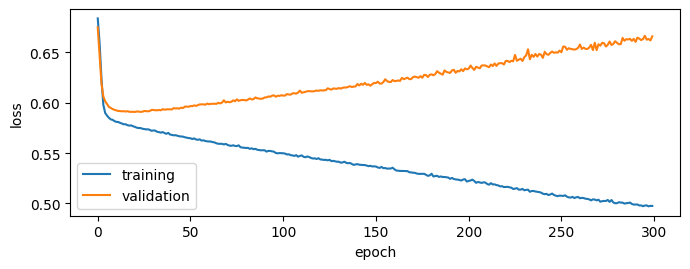

In [ ]:
h = np.array(history)                       # (300, 2): training, validation
plt.figure(figsize=(7, 2.8))
plt.plot(h[:, 0], label="training")
plt.plot(h[:, 1], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.tight_layout()
plt.show()

### Overfitting

The validation loss falls with the training loss for about ten epochs and then levels off: its lowest value, 0.591, comes in epoch 21, and from epoch 10 to epoch 40 it stays within 0.0028 of that. After epoch 40 the two curves part. The training loss keeps falling, to 0.497 by epoch 300, while the validation loss rises, to 0.607 at epoch 100 and 0.666 at epoch 300. The network is fitting the particular rows it is trained on rather than the relationship between the features and the label, which is called **overfitting**. Training for 40 epochs ends at the bottom of the validation curve.

### Early stopping

In [ ]:
torch.manual_seed(42)
net = Net(17)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
best_loss, best_epoch, best_state = float("inf"), 0, None
for epoch in range(300):
    train_epoch(net, opt, x, y)
    val_loss = evaluate(net, xv_t, yv_t)
    if val_loss < best_loss:
        best_loss, best_epoch = val_loss, epoch
        best_state = copy.deepcopy(net.state_dict())
    elif epoch - best_epoch >= 20:          # 20 epochs without improvement
        break
net.load_state_dict(best_state)             # the weights of the best epoch

print((epoch, best_epoch, round(best_loss, 4)))      # -> (40, 20, 0.5908)
print((predict(features(test)) == yte).mean())     # -> 0.6598

(40, 20, 0.5908)
0.6598258706467661


Early stopping monitors the validation loss during training. It keeps the weights of the best epoch so far, and stops once the validation loss has not improved for a set number of epochs, the patience. With a patience of 20 this run stops after epoch 41 and restores the weights of epoch 21, which are indices 40 and 20 counted from 0. `state_dict()` returns a dictionary of the parameter tensors themselves, not copies, so without `copy.deepcopy` the saved state would change with every later update and end as the last weights rather than the best ones. Restored, the network scores 0.660 on the test rows, against 0.659 for the 40-epoch run on all 4960 training rows.

**Try it.** Run the early-stopping loop with a patience of 5 and of 50, and compare the epochs it stops at and the weights it restores.

## 09 Saving, loading and the GPU

A trained network consists of its class, which is code, and its parameters, which are saved to a file and loaded into a new instance of the same class.

In [ ]:
torch.save(net.state_dict(), "churn_net.pt")    # the parameters, by name

net2 = Net(17)                                  # a new instance with random weights
net2.load_state_dict(torch.load("churn_net.pt"))
net2.eval()
print(torch.equal(net(x), net2(x)))             # -> True   the same outputs, bit for bit

True


`state_dict()` maps each parameter name to its tensor, `stack.0.weight` to its `(32, 17)` matrix and so on. `torch.save` writes it to a file, under 8 kB for this network, and `load_state_dict` copies the tensors into a new instance, which then computes exactly what the original does. Loading into a class whose parameters have other names, for example one that assigns its layers to attributes `fc1`, `fc2` and `out` instead of an `nn.Sequential` named `stack`, raises an error that lists the missing and the unexpected names, so the class definition has to be kept with the file. `eval()` is called before predicting, following the PyTorch tutorial on saving models, so that layers such as dropout switch to their prediction-time behaviour.

### Training on a GPU

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(42)
net = Net(17).to(device)                        # every parameter moved, in place
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
x, y = torch.tensor(xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32)

for epoch in range(40):
    perm = torch.randperm(len(x))
    for i in range(0, len(x), 128):
        b = perm[i:i + 128]
        xb, yb = x[b].to(device), y[b].to(device)    # each batch to the model's device
        opt.zero_grad()
        loss = loss_fn(net(xb), yb)
        loss.backward()
        opt.step()

with torch.no_grad():
    logits = net(torch.tensor(xte, dtype=torch.float32).to(device))
    pred = (torch.sigmoid(logits) > 0.5).long().cpu().numpy()     # back to main memory
print((pred == yte).mean())                     # -> 0.6586   on a GPU, as on the CPU

0.6585820895522388


Running the training loop on a GPU takes three changes. The model is moved once with `.to(device)`, which moves its parameters in place and returns the model. Every batch is moved to the same device before the forward pass. Results are copied back to main memory with `.cpu()` before they are converted to NumPy arrays. Choosing the device once, in the first line, lets the same code run where there is no GPU. When the whole training matrix fits in GPU memory, moving `x` and `y` once before the loop saves a copy per batch. The result can differ slightly from a CPU run, because floating-point sums computed in a different order round differently; here the GPU run and the CPU run both get 1059 of the 1608 test rows right.

### Further reading

- [The PyTorch basics tutorial](https://docs.pytorch.org/tutorials/beginner/basics/intro.html), which covers tensors, autograd, modules and the loop in that order.
- [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), which states the rearrangement that makes it stable, and the `pos_weight` argument.
- [torch.optim](https://docs.pytorch.org/docs/stable/optim.html), for what `step()` does and the arguments Adam takes.
- [torch.utils.data](https://docs.pytorch.org/docs/stable/data.html), for `Dataset`, `DataLoader`, samplers and `collate_fn`.
- [The datasets and dataloaders tutorial](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html).
- [Saving and Loading Models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html), on `state_dict`, `eval()` and the copy required for a best-epoch checkpoint.